# Emotion Detection System: Exploratory Data Analysis

This notebook explores **FER-2013** before any model is trained. It answers these questions:

1. How many images are there, and how are they split?
2. How are the seven emotion classes distributed, and how imbalanced is the data?
3. Do train, validation and test share the same class mix?
4. What do the images look like, and how do pixel intensities behave?
5. Are there data-quality problems, such as blank images or duplicates?

The findings drive the preprocessing and class-imbalance decisions in `src/`. Every plot is saved to `results/`.

> Run from the project root virtual environment. The dataset must be prepared first with `python -m src.data_loader --download`; see `data/README.md`.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

from src import config
from src.data_loader import load_fer2013, class_distribution
from src.utils import set_plot_style, save_fig, SERIES_COLORS, TEXT_PRIMARY, TEXT_SECONDARY

set_plot_style()
pd.set_option("display.precision", 2)
EMOTIONS = config.EMOTIONS
SPLITS = ["train", "val", "test"]
SPLIT_COLORS = dict(zip(SPLITS, SERIES_COLORS[:3]))
rng = np.random.default_rng(config.SEED)
print("Interpreter:", sys.executable)

Interpreter: C:\Users\Kashish Arya\Downloads\Emotion detection Project\.venv\Scripts\python.exe


## 2. Dataset overview

In [2]:
data = load_fer2013()

overview = pd.DataFrame({
    split: {
        "images": len(y),
        "share of dataset (%)": 100 * len(y) / sum(len(v[1]) for v in data.values()),
        "image shape": "x".join(map(str, x.shape[1:])),
        "dtype": str(x.dtype),
        "pixel min": int(x.min()),
        "pixel max": int(x.max()),
    }
    for split, (x, y) in data.items()
}).T
print("Total images:", sum(len(v[1]) for v in data.values()))
overview

Total images: 35887


,images,share of dataset (%),image shape,dtype,pixel min,pixel max
train,28709,80.0,48x48,uint8,0,255
val,3589,10.0,48x48,uint8,0,255
test,3589,10.0,48x48,uint8,0,255


**Observations:**
- 35,887 images in total, split 80 / 10 / 10 into the official Training, PublicTest and PrivateTest sets.
- Every image is 48x48 grayscale `uint8` and uses the full 0-255 range. No resizing is needed for a model with a 48x48 input.

## 3. Class distribution and imbalance

In [3]:
x_train, y_train = data["train"]
dist = class_distribution(y_train).to_frame()
dist["share (%)"] = 100 * dist["count"] / dist["count"].sum()
dist["majority / class ratio"] = dist["count"].max() / dist["count"]
dist.sort_values("count", ascending=False)

,count,share (%),majority / class ratio
Happy,7215,25.13,1.00
Neutral,4965,17.29,1.45
Sad,4830,16.82,1.49
Fear,4097,14.27,1.76
Angry,3995,13.92,1.81
Surprise,3171,11.05,2.28
Disgust,436,1.52,16.55


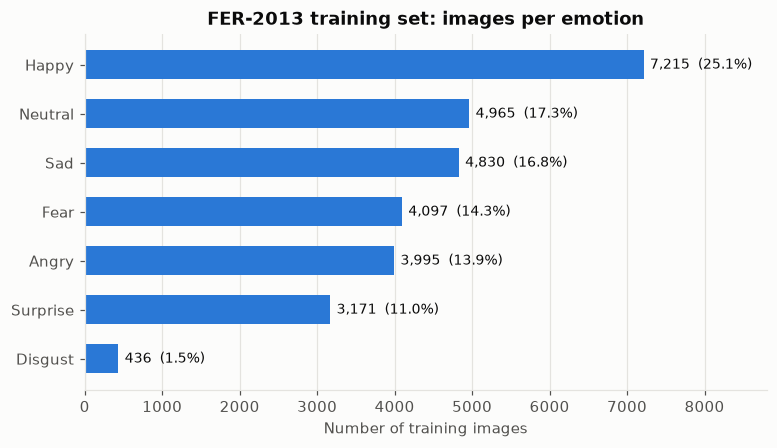

In [4]:
order = dist.sort_values("count").index
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(order, dist.loc[order, "count"], color=SERIES_COLORS[0], height=0.6)
for bar, emotion in zip(bars, order):
    ax.text(bar.get_width() + 80, bar.get_y() + bar.get_height() / 2,
            f"{dist.loc[emotion, 'count']:,}  ({dist.loc[emotion, 'share (%)']:.1f}%)",
            va="center", color=TEXT_PRIMARY, fontsize=9)
ax.set_title("FER-2013 training set: images per emotion")
ax.set_xlabel("Number of training images")
ax.set_xlim(0, dist["count"].max() * 1.22)
ax.grid(axis="y", visible=False)
save_fig(fig, "eda_class_distribution")
plt.show()

### What does imbalance do to accuracy?

Two trivial baselines on the **test** set show why accuracy alone is misleading. One always predicts the majority class (Happy). The other guesses at random, in proportion to the training class frequencies.

In [5]:
x_test, y_test = data["test"]
majority = np.bincount(y_train).argmax()
pred_majority = np.full_like(y_test, majority)
prior = np.bincount(y_train) / len(y_train)
pred_prior = rng.choice(len(EMOTIONS), size=len(y_test), p=prior)

baselines = pd.DataFrame({
    f"always '{EMOTIONS[majority]}'": [accuracy_score(y_test, pred_majority),
                                       f1_score(y_test, pred_majority, average="macro", zero_division=0),
                                       f1_score(y_test, pred_majority, average="weighted", zero_division=0)],
    "random by class frequency": [accuracy_score(y_test, pred_prior),
                                  f1_score(y_test, pred_prior, average="macro", zero_division=0),
                                  f1_score(y_test, pred_prior, average="weighted", zero_division=0)],
}, index=["accuracy", "macro F1", "weighted F1"]).T
baselines

,accuracy,macro F1,weighted F1
always 'Happy',0.24,0.06,0.10
random by class frequency,0.17,0.14,0.17


**Observations:**
- **Happy** is the largest class: 25.1% of training images (7,215).
- **Disgust** is the smallest: 1.5% of training images (436), **16.5x** fewer than Happy. Every other class is within about 2.3x of Happy, so the imbalance is concentrated in one class.
- The baselines show why accuracy alone is misleading. Always predicting *Happy* gives **24% test accuracy** but only **0.06 macro F1**, because macro F1 averages the seven per-class F1 scores equally, so ignoring six classes is heavily penalised.
- **Decision:** train with class weights computed from the training counts, and report macro F1 and weighted F1 alongside accuracy. Any useful model must clearly beat these baselines.

## 4. Train / validation / test comparison

In [6]:
split_share = pd.DataFrame({
    split: 100 * class_distribution(y) / len(y) for split, (x, y) in data.items()
})
split_counts = pd.DataFrame({split: class_distribution(y) for split, (x, y) in data.items()})
display(split_counts.assign(total=split_counts.sum(axis=1)))
split_share.assign(**{"max gap (pp)": split_share.max(axis=1) - split_share.min(axis=1)})

,train,val,test,total
Angry,3995,467,491,4953
Disgust,436,56,55,547
Fear,4097,496,528,5121
Happy,7215,895,879,8989
Sad,4830,653,594,6077
Surprise,3171,415,416,4002
Neutral,4965,607,626,6198


,train,val,test,max gap (pp)
Angry,13.92,13.01,13.68,0.90
Disgust,1.52,1.56,1.53,0.04
Fear,14.27,13.82,14.71,0.89
Happy,25.13,24.94,24.49,0.64
Sad,16.82,18.19,16.55,1.64
Surprise,11.05,11.56,11.59,0.55
Neutral,17.29,16.91,17.44,0.53


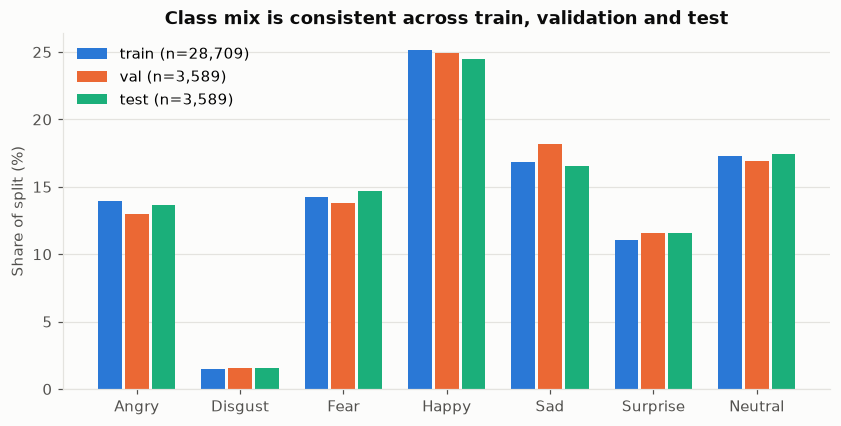

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.26
xpos = np.arange(len(EMOTIONS))
for i, split in enumerate(SPLITS):
    ax.bar(xpos + (i - 1) * width, split_share[split], width=width - 0.03,
           color=SPLIT_COLORS[split], label=f"{split} (n={len(data[split][1]):,})")
ax.set_xticks(xpos, EMOTIONS)
ax.set_ylabel("Share of split (%)")
ax.set_title("Class mix is consistent across train, validation and test")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
save_fig(fig, "eda_split_comparison")
plt.show()

**Observations:**
- The class mix is almost identical in all three splits: no class differs by more than 1.6 percentage points (Sad in validation).
- Disgust is about 1.5% everywhere. Validation and test each contain only about 55 Disgust images, so the per-class metrics for Disgust will be **noisy**: a handful of predictions changes its F1 noticeably.
- **Decision:** keep the official splits. They are already stratified, so no re-splitting is needed.

## 5. Example images per emotion

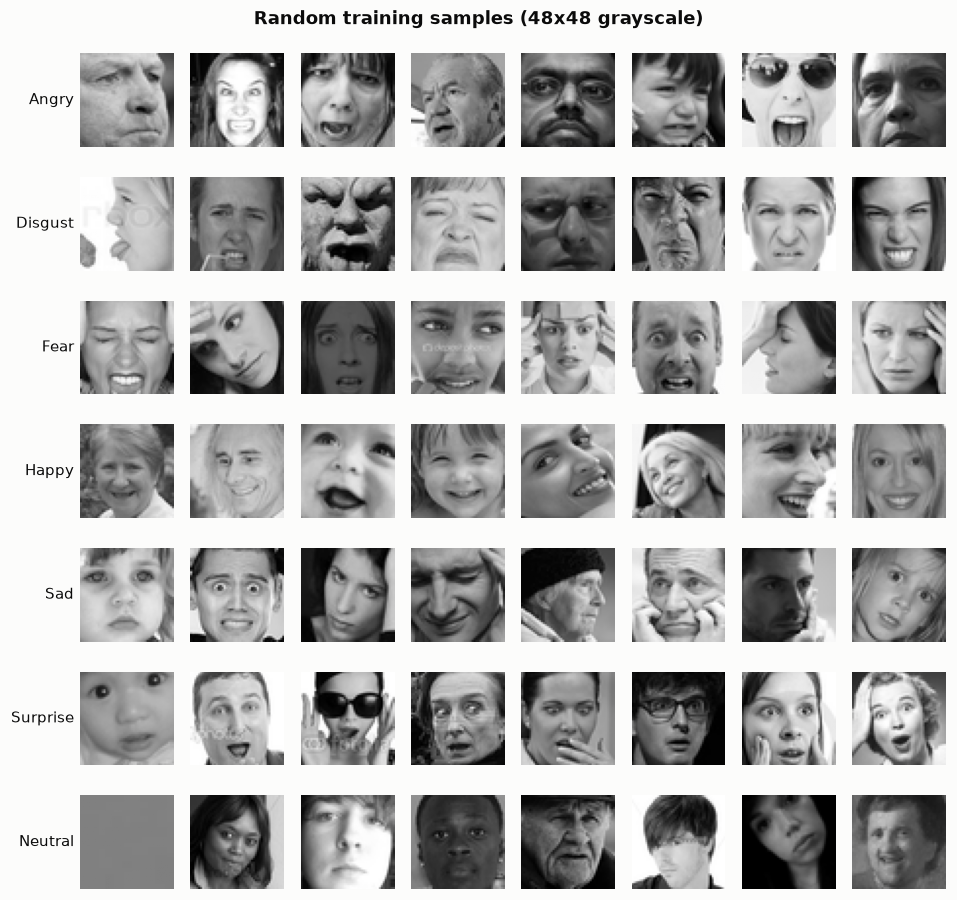

In [8]:
n_per_class = 8
fig, axes = plt.subplots(len(EMOTIONS), n_per_class, figsize=(n_per_class * 1.1, len(EMOTIONS) * 1.2))
for row, emotion in enumerate(EMOTIONS):
    idx = rng.choice(np.flatnonzero(y_train == row), n_per_class, replace=False)
    for col, i in enumerate(idx):
        ax = axes[row, col]
        ax.imshow(x_train[i], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
    axes[row, 0].set_ylabel(emotion, rotation=0, ha="right", va="center", color=TEXT_PRIMARY, fontsize=10)
fig.suptitle("Random training samples (48x48 grayscale)", fontweight="bold", color=TEXT_PRIMARY)
fig.tight_layout()
save_fig(fig, "eda_sample_images")
plt.show()

### Average face per emotion

Averaging every training image of one class shows the expression *template* a model could pick up on, because the faces are roughly aligned.

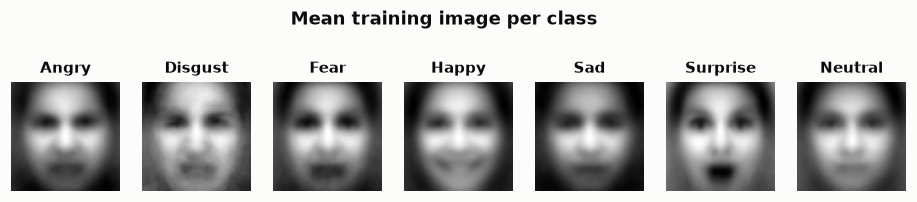

In [9]:
fig, axes = plt.subplots(1, len(EMOTIONS), figsize=(len(EMOTIONS) * 1.5, 2.1))
for i, (ax, emotion) in enumerate(zip(axes, EMOTIONS)):
    ax.imshow(x_train[y_train == i].mean(axis=0), cmap="gray")
    ax.set_title(emotion, fontsize=10)
    ax.axis("off")
fig.suptitle("Mean training image per class", fontweight="bold", color=TEXT_PRIMARY, y=1.04)
save_fig(fig, "eda_mean_faces")
plt.show()

**Observations:**
- Faces are roughly centred and cropped, but they vary a lot in **head pose**, **age**, **lighting** and **occlusion** (hands, sunglasses, hair).
- **Watermarks** from stock-photo sites are visible on some images (for example in the Disgust, Fear and Surprise rows). This is a web-scraping artefact the model could wrongly learn from.
- **Label noise** is visible. Some *Sad* samples look closer to Fear or Surprise, and in this seeded sample the first *Neutral* image is a flat grey square with no face (see Section 7).
- The **mean faces are sharp**, which means the faces are well aligned. The class templates differ in the mouth region: Happy shows a smile, Surprise an open mouth, and Disgust and Angry a tense lower face. The mouth and eye regions are where a CNN should focus, which Grad-CAM can check later.
- **Decision:** because the faces are already aligned, augmentation should stay mild: small rotations, shifts and zooms, plus horizontal flips. Faces are close to symmetric, so a flip does not change the expression.

## 6. Pixel intensity analysis

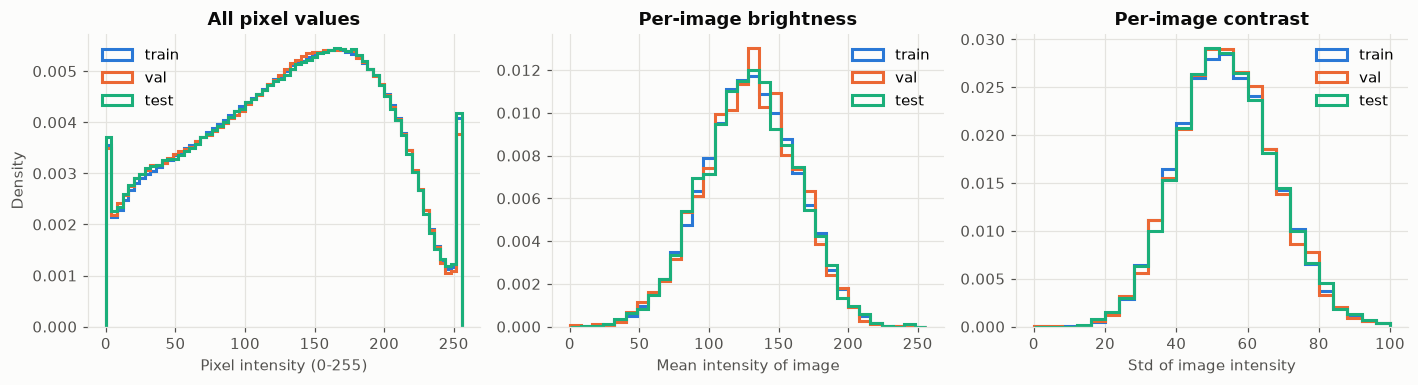

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
bins = np.arange(0, 257, 4)
for split, (x, y) in data.items():
    flat = x.reshape(len(x), -1)
    axes[0].hist(x.ravel(), bins=bins, density=True, histtype="step", linewidth=2,
                 color=SPLIT_COLORS[split], label=split)
    axes[1].hist(flat.mean(axis=1), bins=np.arange(0, 257, 8), density=True, histtype="step", linewidth=2,
                 color=SPLIT_COLORS[split], label=split)
    axes[2].hist(flat.std(axis=1), bins=np.arange(0, 101, 4), density=True, histtype="step",
                 linewidth=2, color=SPLIT_COLORS[split], label=split)
axes[0].set(title="All pixel values", xlabel="Pixel intensity (0-255)", ylabel="Density")
axes[1].set(title="Per-image brightness", xlabel="Mean intensity of image")
axes[2].set(title="Per-image contrast", xlabel="Std of image intensity")
for ax in axes:
    ax.legend()
fig.tight_layout()
save_fig(fig, "eda_pixel_intensity")
plt.show()

In [11]:
stats = []
for split, (x, y) in data.items():
    flat = x.reshape(len(x), -1).astype(np.float32)
    stats.append({"split": split, "pixel mean": flat.mean(), "pixel std": flat.std(),
                  "% pixels = 0": 100 * (flat == 0).mean(), "% pixels = 255": 100 * (flat == 255).mean(),
                  "median image contrast": np.median(flat.std(axis=1))})
display(pd.DataFrame(stats).set_index("split"))

flat_train = x_train.reshape(len(x_train), -1).astype(np.float32)
pd.DataFrame({
    "mean brightness": [flat_train[y_train == i].mean() for i in range(len(EMOTIONS))],
    "mean contrast": [flat_train[y_train == i].std(axis=1).mean() for i in range(len(EMOTIONS))],
}, index=EMOTIONS)

,pixel mean,pixel std,% pixels = 0,% pixels = 255,median image contrast
split,,,,,
train,129.47,65.03,0.69,0.94,53.62
val,128.98,65.01,0.67,0.88,53.59
test,129.08,65.35,0.71,0.90,53.89


,mean brightness,mean contrast
Angry,126.23,54.40
Disgust,135.23,52.20
Fear,135.52,54.66
Happy,129.43,53.12
Sad,121.27,53.72
Surprise,146.26,55.17
Neutral,123.90,54.26


**Observations:**
- The pixel, brightness and contrast distributions of train, validation and test **overlap almost perfectly**, so there is no distribution shift between splits.
- The spikes at **0 and 255** (about 0.7% and 0.9% of pixels) are clipped pixels: saturated highlights and black borders or padding.
- Mean brightness **differs by class**: Surprise images are the brightest (146) and Sad the darkest (121). This is a dataset bias (sources and lighting), not a property of the expression. A model could pick up brightness as a shortcut.
- **Decision:** scale pixels to [0, 1] by dividing by 255, the same at training and inference time. Per-image contrast is similar for every class (52-55), so heavier normalisation is not needed. A small random brightness and contrast augmentation is worth trying, to discourage the brightness shortcut.

## 7. Data quality: near-blank images

An image whose pixel standard deviation is below 1 is effectively a single flat colour. It contains no face, but it still carries an emotion label.

In [12]:
BLANK_STD = 1.0
blank_rows = []
for split, (x, y) in data.items():
    stds = x.reshape(len(x), -1).std(axis=1)
    for i in np.flatnonzero(stds < BLANK_STD):
        blank_rows.append({"split": split, "index": i, "label": EMOTIONS[y[i]],
                           "pixel std": stds[i], "mean value": x[i].mean()})
blank = pd.DataFrame(blank_rows)
print(f"Near-blank images: {len(blank)}")
display(blank.groupby(["split", "label"]).size().rename("count").to_frame())
blank

Near-blank images: 13


count
split label          
train Angry         7
      Happy         1
      Neutral       2
      Sad           1
      Surprise      1
val   Angry         1

,split,index,label,pixel std,mean value
0,train,2171,Neutral,0.64,128.3
1,train,6458,Angry,0.00,0.0
2,train,7629,Happy,0.00,0.0
3,train,10423,Sad,0.00,0.0
4,train,11286,Angry,0.00,0.0
5,train,13148,Angry,0.00,0.0
6,train,13402,Angry,0.00,0.0
7,train,13988,Surprise,0.00,0.0
8,train,15894,Angry,0.00,0.0
9,train,22198,Angry,0.00,0.0


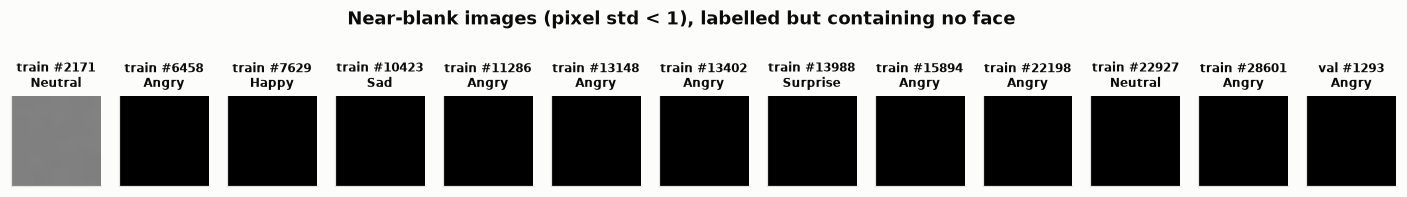

In [13]:
fig, axes = plt.subplots(1, len(blank), figsize=(len(blank) * 1.25, 1.9))
for ax, (_, r) in zip(np.atleast_1d(axes), blank.iterrows()):
    ax.imshow(data[r["split"]][0][r["index"]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{r['split']} #{r['index']}\n{r['label']}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Near-blank images (pixel std < 1), labelled but containing no face",
             fontweight="bold", color=TEXT_PRIMARY, y=1.12)
save_fig(fig, "eda_near_blank_images")
plt.show()

### Sanity check of the threshold

How many images sit just above the cut-off? If the low-contrast range is empty, the threshold is not hiding a larger problem.

In [14]:
all_stds = np.concatenate([x.reshape(len(x), -1).std(axis=1) for x, _ in data.values()])
pd.Series({f"std < {t}": int((all_stds < t).sum()) for t in [1, 5, 10, 15, 20]}, name="images")

std < 1     13
std < 5     14
std < 10    15
std < 15    19
std < 20    96
Name: images, dtype: int64

**Observations:**
- **13 images contain no face** (12 in train, 1 in validation, 0 in test). Twelve are completely black and one is a flat grey square, yet each carries an emotion label (8 of the 13 are *Angry*).
- Above the cut-off the counts grow gradually (13 below std 1, then 15 below 10 and 19 below 15), so these 13 form a clearly separate group of corrupt samples.
- **Decision:** drop these images from train and validation. They teach the model nothing about faces, and they bias it toward predicting *Angry* for dark inputs. The test set has none, so it stays exactly the official set.

## 8. Data quality: duplicate images

FER-2013 was scraped from the web, so the same picture can appear more than once. Duplicates **across** splits leak information from training into evaluation. Duplicates **with conflicting labels** show label noise.

In [15]:
hashes = {split: np.array([hashlib.md5(img.tobytes()).hexdigest() for img in x])
          for split, (x, _) in data.items()}
non_blank = {split: data[split][0].reshape(len(data[split][0]), -1).std(axis=1) >= BLANK_STD for split in SPLITS}

h_train = pd.Series(hashes["train"][non_blank["train"]])
print(f"Exact duplicate images inside train (excluding blanks): {int(h_train.duplicated().sum())}")

train_set = set(h_train)
for split in ["val", "test"]:
    overlap = sum(h in train_set for h in hashes[split][non_blank[split]])
    print(f"{split} images that also appear in train: {overlap} ({100 * overlap / len(hashes[split]):.2f}% of {split})")

Exact duplicate images inside train (excluding blanks): 1226
val images that also appear in train: 279 (7.77% of val)
test images that also appear in train: 288 (8.02% of test)


In [16]:
# Duplicates whose copies carry different labels (label noise)
frames = [pd.DataFrame({"hash": hashes[s][non_blank[s]], "label": data[s][1][non_blank[s]]}) for s in SPLITS]
allh = pd.concat(frames, ignore_index=True)
groups = allh.groupby("hash")["label"].agg(["size", "nunique"])
dupe_groups = groups[groups["size"] > 1]
print(f"Images that occur more than once (across all splits): {len(dupe_groups)}")
print(f"... of which copies disagree on the label: {int((dupe_groups['nunique'] > 1).sum())}")

Images that occur more than once (across all splits): 1515
... of which copies disagree on the label: 56


**Observations:**
- **1,226** training images are exact copies of another training image.
- **288 test images (8.0%)** and **279 validation images (7.8%)** also appear, pixel for pixel, in the training set. This is **data leakage**: the model has already seen these exact images during training, so its score on them is optimistic.
- **56** duplicated images carry *different* labels in different copies. This is direct evidence of label noise.
- **Decision:** the official test set is kept unchanged, so results can be compared with published FER-2013 numbers. The final evaluation will **also** report metrics on the **deduplicated test subset** (test images that do not appear in train), which is the more honest estimate of performance on unseen faces.

## 9. Summary and decisions for the pipeline

| Finding | Evidence | Pipeline decision |
|---|---|---|
| Severe imbalance in one class | Disgust is 1.5% of train, 16.5x smaller than Happy | Class weights computed from training counts; report macro F1 and weighted F1, not only accuracy |
| Accuracy is a misleading metric | Always predicting Happy: 24% accuracy, 0.06 macro F1 | Use these baselines as the floor the model must clearly beat |
| Splits are consistent | Class shares within 1.6 pp; pixel statistics overlap | Keep the official Training / PublicTest / PrivateTest splits |
| Faces are aligned, 48x48 grayscale | Sharp mean faces; uniform shape | 48x48x1 input, scaled to [0, 1]; mild augmentation only (flip, about 10 degree rotation, 10% zoom and shift) |
| Brightness differs by class | Surprise mean 146 vs. Sad 121 | Consider a small random brightness and contrast augmentation |
| 13 images with no face | 12 black and 1 grey, all labelled | Remove from train and validation (the test set has none) |
| Train/test leakage | 8.0% of test images are exact copies of train images | Report metrics on both the full official test set and its deduplicated subset |
| Label noise | 56 duplicated images with conflicting labels; visibly ambiguous samples | Expect a ceiling well below 100%; human accuracy on FER-2013 is estimated at about 65% |
| Small minority test sample | About 55 Disgust test images | Treat per-class Disgust metrics as high-variance |

These decisions are carried into `src/preprocessing.py` and `src/train.py`.